# Project Prediksi Selling Price Produk TL-WR840N (Harga Penjualan) Berdasarkan Original Price (Harga yang di set toko di awal penjualan) Menggunakan Algoritma Simple Linear Regression

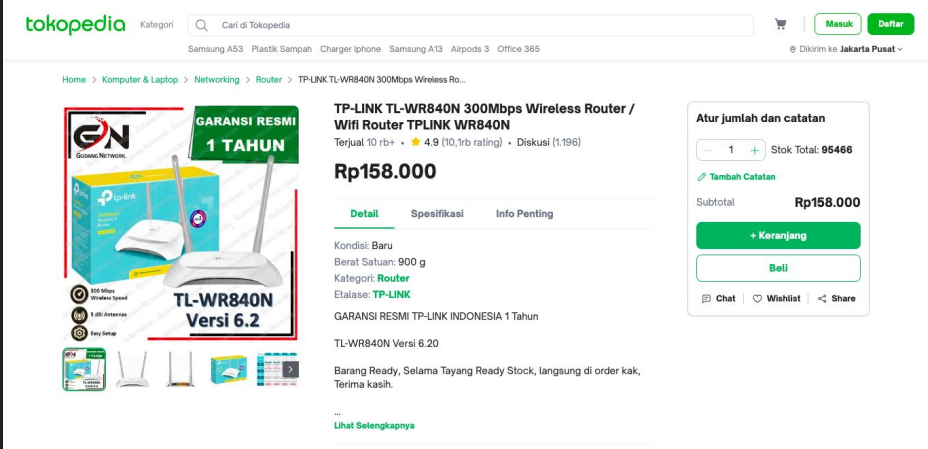

# Studi Kasus

Sebuah Perusahaan Elektronik Internet ingin anda memprediksi harga jual produk dengan SKU (TLWR840N) di Platform Tokopedia.

SOAL: Buatlah Pemodelan data yang meramalkan produk
TL WR80N dengan menggunakan metode Simple
Linear Regression !

# A. Data Preparation

A.1 Import Libraries

In [193]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
pd.set_option('display.float_format', '{:.6f}'.format)

A.2 Import Dataset

In [194]:
df = pd.read_excel("Datains - Marcella - Price Monitoring TP-Link_TP-Link Price Monitoring_Table.xlsx")
df = df[df['Merchant'] == 'tokopedia']

A.3 Melihat 5 data teratas

In [195]:
df.head()

,Date,Last Crawling,SKU Name,Product Name,Url Product,Seller,Merchant,Stock,Item Condition,Filter,Flag,Bottom Price,Original Price,Discount,Selling Price,Discrepancy,Sales Quantity,Sales Revenue
0,2022-10-22,2022-10-22,TL WR840N,TP-Link TL-WR840N 2 Antenna 300Mbps Wireless N...,https://tokopedia.com/ccplace/tp-link-tl-wr840...,ccplace shop,tokopedia,In Stock,baru,Above,Please Check,155000,231000,0,231000,0.014903,0,0
1,2022-10-22,2022-10-22,TL WR840N,Promo TP-LINK TL-WR840N Wireless Router 300Mbp...,https://tokopedia.com/gilsaashopp/promo-tp-lin...,gilsaa_shopp,tokopedia,In Stock,baru,Above,Please Check,155000,218800,0,218800,0.014116,0,0
2,2022-10-22,2022-10-22,TL WR840N,Tp-Link TL-WR840N 300Mbps Wireless N Speed Rou...,https://tokopedia.com/ccwinta/tp-link-tl-wr840...,ccwinta shop,tokopedia,In Stock,baru,Above,Please Check,155000,227000,0,227000,0.014645,0,0
3,2022-10-22,2022-10-22,TL WR840N,JARINGAN TP-LINK TL-WR 840N TL-WR840N 300MBps ...,https://tokopedia.com/belsa/jaringan-tp-link-t...,BELSA_SHOP,tokopedia,In Stock,baru,Above,Please Check,155000,263000,0,263000,0.016968,0,0
4,2022-10-22,2022-10-22,TL WR840N,TPLink TL-WR840N Router Wireless WiFi 300Mbps ...,https://tokopedia.com/ccwinta/tplink-tl-wr840n...,ccwinta shop,tokopedia,In Stock,baru,Above,Please Check,155000,236000,0,236000,0.015226,0,0


A.4 Melihat informasi dari dataset

In [196]:
df.info()

<class 'pandas.DataFrame'>
Index: 30328 entries, 0 to 32771
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            30328 non-null  datetime64[us]
 1   Last Crawling   30328 non-null  datetime64[us]
 2   SKU Name        30328 non-null  str           
 3   Product Name    30328 non-null  str           
 4   Url Product     30328 non-null  str           
 5   Seller          30328 non-null  object        
 6   Merchant        30328 non-null  str           
 7   Stock           30328 non-null  str           
 8   Item Condition  30328 non-null  str           
 9   Filter          30328 non-null  str           
 10  Flag            30328 non-null  str           
 11  Bottom Price    30328 non-null  int64         
 12  Original Price  30328 non-null  object        
 13  Discount        30328 non-null  object        
 14  Selling Price   30328 non-null  int64         
 15  Discrepancy     30

pada data diatas Ada 32772 baris dan 18 kolom, pada kolom tersebut memiliki tipe data object, integer, float dan datetime.

Namun ada yang tidak sesuai seperti Original Price yang harusnya Numerik tapi terbaca object, oleh karena itu kami akan menangani kolom tersebut terlebih dahulu sebelum memproses data

A.5 Melihat data duplikat

In [197]:
def cek_duplikat(df):
    duplicated_df = df[df.duplicated()]
    index_list = duplicated_df.index.tolist()
    print(f'Kolom yang terduplikat : ')
    print(duplicated_df)
    print(f'Jumlah data duplikat : {df.duplicated().sum()}')
    print(f'Baris : {index_list}')

In [198]:
cek_duplikat(df)

Kolom yang terduplikat : 
Empty DataFrame
Columns: [Date, Last Crawling, SKU Name, Product Name, Url Product, Seller, Merchant, Stock, Item Condition, Filter, Flag, Bottom Price, Original Price, Discount, Selling Price, Discrepancy, Sales Quantity, Sales Revenue]
Index: []
Jumlah data duplikat : 0
Baris : []


Berdasarkan hasil di atas tidak ada kolom yang terdeteksi duplikat

A.6 Melihat data kosong

In [199]:
df.isna().sum()

Date              0
Last Crawling     0
SKU Name          0
Product Name      0
Url Product       0
Seller            0
Merchant          0
Stock             0
Item Condition    0
Filter            0
Flag              0
Bottom Price      0
Original Price    0
Discount          0
Selling Price     0
Discrepancy       0
Sales Quantity    0
Sales Revenue     0
dtype: int64

Berdasarkan hasil di atas tidak ada data yang kosong (Missing value)

A.10 Mengecek isi kolom Discount

In [206]:
df['Discount'].unique()

array([0, 0.07, 0.18, 0.23, 0.62, 0.1, 0.05, 0.31, 0.53, 0.63, '-', 0.29,
       0.01, 0.03, 0.24, 0.08, 0.09, 0.11, 0.02, 0.16, 0.12, 0.22, 0.59,
       0.46, 0.35, 0.2, 0.13], dtype=object)

- Tindakan yang akan kami lakukan selanjutnya yaitu mengubah nilai '-' menjadi nan

In [207]:
df['Discount'] = df['Discount'].replace({
    '-': np.nan
})

A.11 Mengecek isi kolom Original Price

In [209]:
df['Original Price'].unique()

array([231000, 218800, 227000, ..., 295464, 272364, 233621],
      shape=(3118,), dtype=object)

A.11 Karena berbentuk array dan nilai kontinu kami mengecek sekali lagi untuk meyakinkan ada anomaly atau tidak 

In [210]:
df['Original Price'] = df['Original Price'].astype(str)
unique = np.unique(df['Original Price'])

for i in unique:
    if i == '-':
        print('Ada anomaly :', i)

Ada anomaly : -


A.12 Ternyata ada ada anomaly sehingga kami melakukan penanganan

In [211]:
df['Original Price'] = df['Original Price'].replace({
    '-': np.nan
})

A.13 Menangani missing value tadi dengan menghapusnya

In [213]:
df = df.dropna()

A.14 Menampilkan Statistik Deskriptif Setelah penanganan data

In [214]:
df.describe()

,Date,Last Crawling,Bottom Price,Original Price,Discount,Selling Price,Discrepancy,Sales Quantity,Sales Revenue
count,30326,30326,30326.000000,30326.000000,30326.000000,30326.000000,30326.000000,30326.000000,30326.000000
mean,2022-09-24 08:34:54.994394,2022-09-24 08:34:54.994394,155000.000000,269645.194106,0.000288,269555.815604,0.017286,7.321836,1152789.913605
min,2022-09-20 00:00:00,2022-09-20 00:00:00,155000.000000,25000.000000,0.000000,25000.000000,0.000000,0.000000,0.000000
25%,2022-09-20 00:00:00,2022-09-20 00:00:00,155000.000000,216000.000000,0.000000,216000.000000,0.013935,0.000000,0.000000
50%,2022-09-20 00:00:00,2022-09-20 00:00:00,155000.000000,244000.000000,0.000000,244000.000000,0.015742,0.000000,0.000000
75%,2022-09-29 00:00:00,2022-09-29 00:00:00,155000.000000,291600.000000,0.000000,291500.000000,0.018806,0.000000,0.000000
max,2022-10-22 00:00:00,2022-10-22 00:00:00,155000.000000,26164600.000000,0.630000,26164600.000000,1.688039,33740.000000,5229700000.000000
std,NaN,NaN,0.000000,244050.614126,0.010898,244056.881375,0.015828,280.833783,43615348.085352


Berdasarkan hasil statistik data diatas:

- Kolom Bottom Price memiliki nilai yang sama pada seluruh baris yaitu 155.000 
- Kolom Selling Price memiliki harga router di kisaran angka 216.000 hingga 291.000 (Q1 - Q3) namun pada nilai minimal dan maximal ada indikasi hal yang aneh yaitu nilai minimal router 25.000 dan nilai maximal 26.164.600 hal ini perlu kami analisis lebih lanjut sebelum menentukan apakah nilai tersebut valid. Selain itu nilai Selling Price dengan Original Price dari nilai minimum hingga maximum memiliki nilai yang hampir sama, sehingga harus di analisis lebih lanjut pada tahap EDA
- Nilai dari kolom Sales Quantity dari nilai minimum hingga Q3 memiliki nilai 0, sedangkan pada nilai maximum ada pada 33.740. Mungkin saja ada indikasi pengguna tokopedia lebih sering belanja pada toko terpercaya yang banyak penjualannya.
- Sales Revenue hampir sama seprti kolom Sales Quantity yaitu nilai minimum hingga Q3 memiliki nilai 0 dan nilai maximum yang tinggi. Kami mengindikasikan bahwa Sales Revenue ini dari toko yang sama seperti nilai maximum Sales Quantity.
- Pada kolom Discount nilai minimal hingga Q3 memiliki nilai 0, namun pada nilai maximum memiliki Discount yaitu 0.6 yang mengindikasikan toko merchant pada tokopedia jarang memberi Discount

# B. EDA

B.1  Menampilkan histogram untuk melihat distribusi data

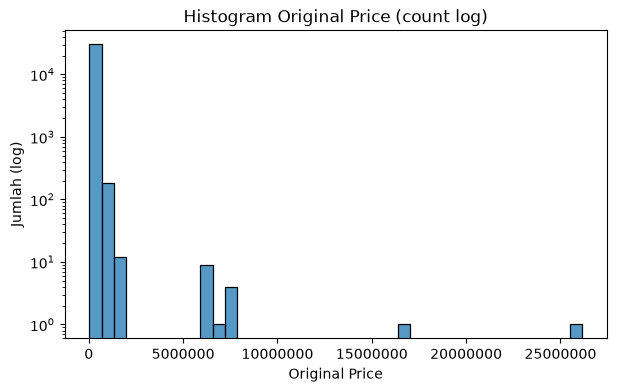

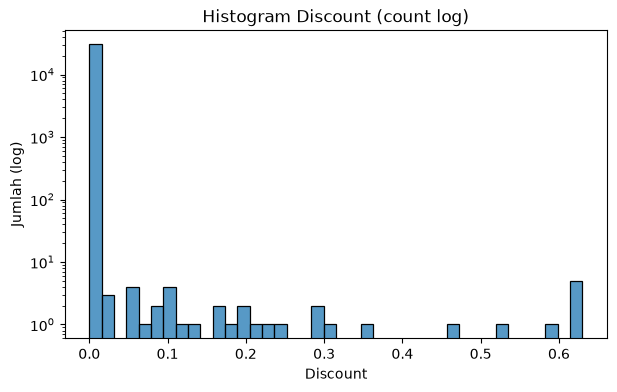

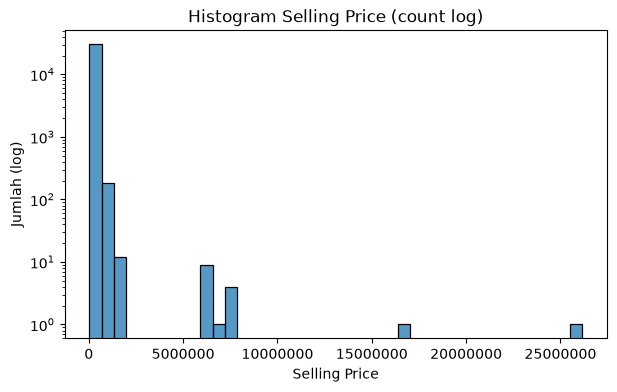

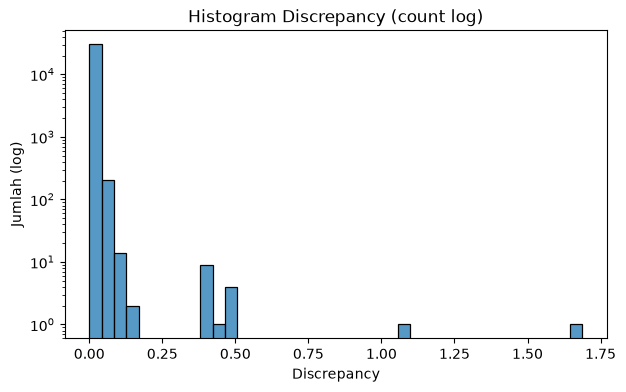

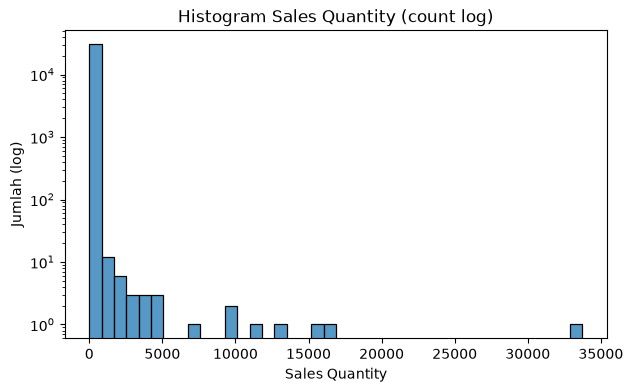

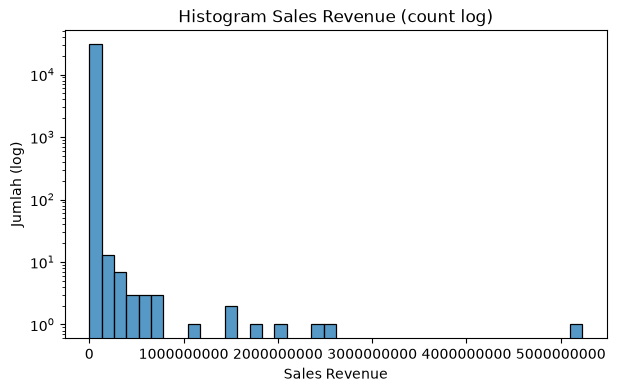

In [215]:
num = df.select_dtypes(include=np.number)
num = num.loc[:, num.nunique() > 1]    # buang kolom konstan, misal Bottom Price

for col in num.columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(num[col].dropna(), bins=40)
    plt.yscale('log')                    # jumlah (count) pakai skala log
    plt.ticklabel_format(style='plain', axis='x', useOffset=False)
    plt.title(f'Histogram {col} (count log)')
    plt.xlabel(col)
    plt.ylabel('Jumlah (log)')
    plt.show()

- Berdasarkan hasil di atas distribusi data tersebut tidak normal atau miring / skewed
- Mayoritas Original Price ada di nilai 100.000-200.000 tapi ada nilai yang sangat jauh dari mayoritas di angka sekitar 25 juta keatas sehingga perlu analisis lanjutan.
- Mayoritas toko tidak memberikan Discount karena ada indikasi bahwa harga yang di jual adalah harga pabrik (bottom price)
- Mayoritas nilai Selling Price memiliki indikasi kesamaan dengan Original Price
- Sales Quantity terindikasi bahwa mayoritas toko memiliki jumlah penjualan yang relatif rendah, sedangkan hanya sebagian kecil toko yang memiliki jumlah penjualan jauh lebih tinggi.
- Sales Revenue terindikasi bahwa mayoritas toko memiliki pendapatan yang relatif rendah, sedangkan hanya sebagian kecil toko yang menghasilkan pendapatan jauh lebih tinggi.

B.2 Menampilkan Boxplot, untuk melihat outlier

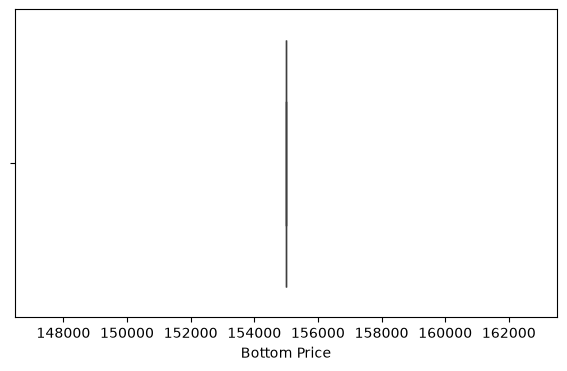

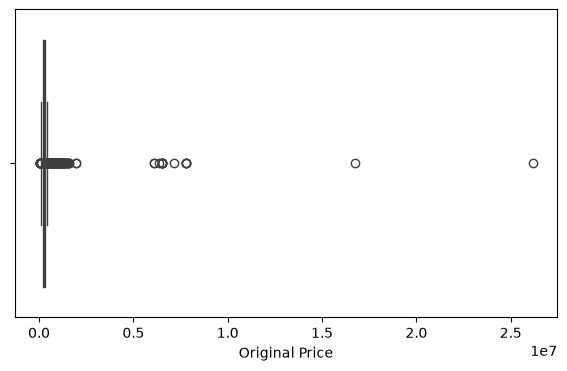

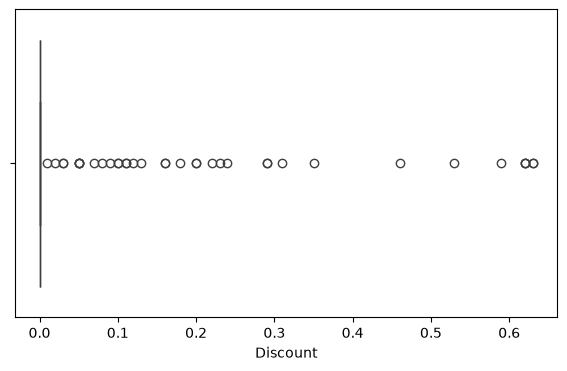

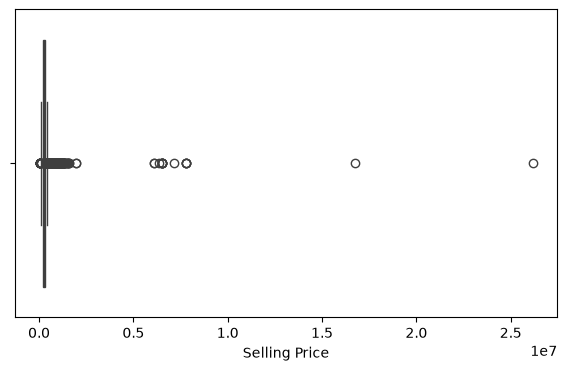

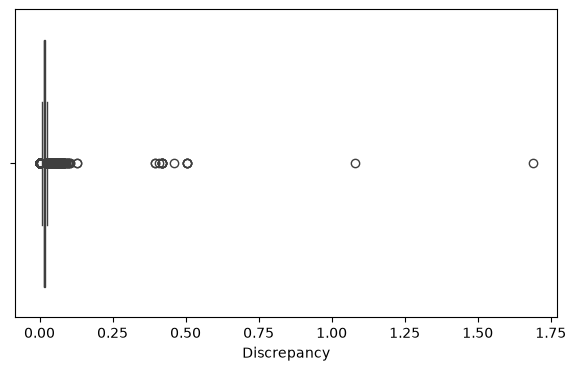

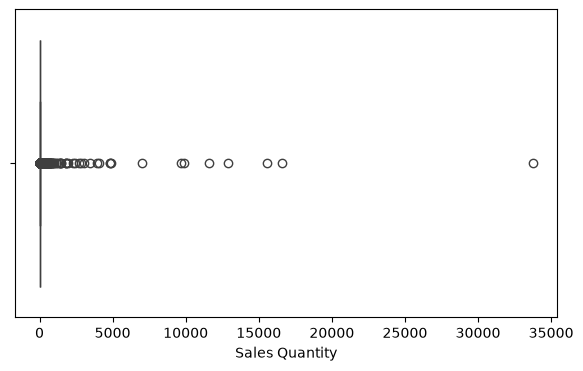

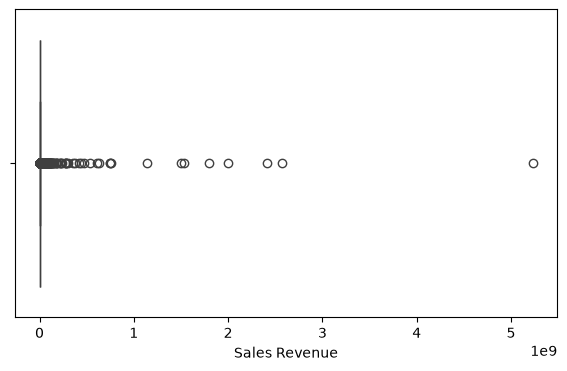

In [216]:
for i in df.select_dtypes(include=np.number).columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[i])
    plt.show()

berdasarkan hasil di atas, terdapat banyak titik-titik outlier. Hal ini perlu di analisis lebih lanjut apakah titik-titik tersebut adalah outlier atau nilai yang valid.

B.3 Menampilkan Dataset dengan urutan Sales Quantity terbanyak

In [217]:
df_new = df.sort_values(
    by=['Sales Quantity', 'Selling Price'],
    ascending=[False, False]
)
df_new.head(5)

,Date,Last Crawling,SKU Name,Product Name,Url Product,Seller,Merchant,Stock,Item Condition,Filter,Flag,Bottom Price,Original Price,Discount,Selling Price,Discrepancy,Sales Quantity,Sales Revenue
17885,2022-09-20,2022-09-20,TL WR840N,TP-LINK TL-WR840N 300Mbps Wireless Router / Wi...,https://tokopedia.com/gudangnet/tp-link-tl-wr8...,Gudang Network.,tokopedia,In Stock,baru,Equal,-,155000,155000.000000,0.000000,155000,0.000000,33740,5229700000
17884,2022-09-20,2022-09-20,TL WR840N,TP-LINK TL-WR840N 300Mbps Wireless N Router,https://tokopedia.com/pronetindo/tp-link-tl-wr...,Profesional Network.PT,tokopedia,In Stock,baru,Equal,-,155000,155000.000000,0.000000,155000,0.000000,16613,2575015000
30975,2022-09-20,2022-09-20,TL WR840N,TP-Link TL-WR840N (V4.0) : 300Mbps TPLink WiFi...,https://tokopedia.com/duniacom-srv/tp-link-tl-...,DUNIA COMPUTER &amp; SERVICE,tokopedia,In Stock,baru,Equal,-,155000,155000.000000,0.000000,155000,0.000000,15562,2412110000
5424,2022-10-04,2022-10-04,TL WR840N,TP-LINK TL-WR840N 300MBps Wireless Router WR84...,https://tokopedia.com/tokonetworking/tp-link-t...,Central Electronic,tokopedia,In Stock,baru,Equal,-,155000,155000.000000,0.000000,155000,0.000000,12867,1994385000
25837,2022-09-20,2022-09-20,TL WR840N,TL-WR840N TP-Link 300Mbps Router Wireless N Speed,https://tokopedia.com/sanjayacomtronix/tl-wr84...,SANJAYA COMTRONIX,tokopedia,In Stock,baru,Equal,-,155000,155000.000000,0.000000,155000,0.000000,11609,1799395000


Berdasarkan hasil di atas adanya indikasi bahwa mayoritas pengguna lebih memilih toko dengan harga router yang paling murah.

B.4 Menampilkan list apakah ada seller yang mengunggah produk lebih dari 1

In [218]:
jumlah = df['Seller'].value_counts()           # jumlah listing per seller, urut dari terbanyak
multi = jumlah[jumlah > 1]                    # hanya seller yang upload lebih dari 1

print(len(multi), 'seller upload lebih dari 1 barang')
print(multi.head(20))                         # 20 teratas

3447 seller upload lebih dari 1 barang
Seller
Dexxter                  108
hendromann67              89
putritidurmart            87
didiyan                   86
FITDELPHIN                84
ASSA_Nanta                83
nana-store2               77
Dizhwar emran             73
Capture Me                73
Galerias                  72
maju berkah_              72
Network Place             70
CicarimanahMajaGrosir     68
HELM SEPEDA FREEZZ        68
Fatimah Ternama           65
seoulthirdy               62
Trickshoot                62
Manan-Berkah              59
MANGAKO_STORE             58
Opaline_official          58
Name: count, dtype: int64
Jumlah seller yang lebih dari 1 :  3447


Berdasarkan hasil di atas, terlihat bahwa banyak seller yang mengunggah lebih dari satu produk. Hal ini mengindikasikan bahwa seller berupaya meningkatkan peluang produknya untuk lebih sering muncul dan mendapatkan perhatian konsumen dibandingkan dengan toko lainnya.

B.5 Mengecek harga terbesar hingga terkecil, karena pada statistik deskriptif dan boxplot di atas ada nilai yang kurang masuk akal/outlier

In [219]:
df.sort_values(by = ['Selling Price'], ascending = [False])

,Date,Last Crawling,SKU Name,Product Name,Url Product,Seller,Merchant,Stock,Item Condition,Filter,Flag,Bottom Price,Original Price,Discount,Selling Price,Discrepancy,Sales Quantity,Sales Revenue
17099,2022-09-20,2022-09-20,TL WR840N,TP-LINK TL-WR840N WIRELESS ROUTER TL WR840N TP...,https://tokopedia.com/rollis-1/tp-link-tl-wr84...,ROLLIS_STORE,tokopedia,In Stock,baru,Above,Please Check,155000,26164600.000000,0.000000,26164600,1.688039,0,0
25806,2022-09-20,2022-09-20,TL WR840N,Wireless Router Router Wifi Tp-Link 300Mbps - ...,https://tokopedia.com/milawear/wireless-router...,mila wear,tokopedia,In Stock,baru,Above,Please Check,155000,16741000.000000,0.000000,16741000,1.080065,0,0
28353,2022-09-20,2022-09-20,TL WR840N,Wireless Router Router Wifi TP-LINK 300Mbps - ...,https://tokopedia.com/archive-tifft1067mart/wi...,Tifft1067mart,tokopedia,In Stock,baru,Above,Please Check,155000,7800000.000000,0.000000,7800000,0.503226,0,0
14653,2022-09-20,2022-09-20,TL WR840N,Wireless Router Router Wifi TP-LINK 300Mbps - ...,https://tokopedia.com/adina78/wireless-router-...,Adin Official Store,tokopedia,In Stock,baru,Above,Please Check,155000,7800000.000000,0.000000,7800000,0.503226,0,0
14698,2022-09-20,2022-09-20,TL WR840N,Wireless Router Router Wifi TP-LINK 300Mbps - ...,https://tokopedia.com/suroto/wireless-router-r...,suroto des,tokopedia,In Stock,baru,Above,Please Check,155000,7800000.000000,0.000000,7800000,0.503226,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25500,2022-09-20,2022-09-20,TL WR840N,nw4b7 BOX DUS TP-LINK TL-WR840N WIRELESS ROUTE...,https://tokopedia.com/indahshop22-1/nw4b7-box-...,indahshop22,tokopedia,In Stock,baru,Below,Please Check,155000,30100.000000,0.000000,30100,0.001942,0,0
26529,2022-09-20,2022-09-20,TL WR840N,dw2c1 BOX DUS TP-LINK TL-WR840N WIRELESS ROUTE...,https://tokopedia.com/nusantarafn3/dw2c1-box-d...,Nusantara FN3,tokopedia,In Stock,baru,Below,Please Check,155000,30100.000000,0.000000,30100,0.001942,0,0
28692,2022-09-20,2022-09-20,TL WR840N,uw1c3 BOX DUS TP-LINK TL-WR840N WIRELESS ROUTE...,https://tokopedia.com/sangdewa19/uw1c3-box-dus...,sangdewa19,tokopedia,In Stock,baru,Below,Please Check,155000,30100.000000,0.000000,30100,0.001942,0,0
16449,2022-09-20,2022-09-20,TL WR840N,gw3f BOX DUS TP-LINK TL-WR840N WIRELESS ROUTER...,https://tokopedia.com/ceetos/gw3f-box-dus-tp-l...,Ceetos Toko,tokopedia,In Stock,baru,Below,Please Check,155000,29300.000000,0.000000,29300,0.001890,0,0


Berdasarkan hasil di atas:

- Untuk selling price tertinggi bisa sampai berjuta-juta karena ada indikasi bahwa metode crawling kurang spesifik, karena crawling yang di jelaskan di soal hanya mencari keyword 'TLWR840N' hal ini menyebabkan data yang ada bisa mengambil link produk yang di jual bukan satuan melainkan grosir.

- Untuk selling price terrendah bisa sampai 25.000-30.000 juga di sebabkan oleh indikasi metode crawling yang kurang spesifik sehingga produk yang di jual murah bukanlah router melainkan seperti box dus router TLWR840N

- Apakah setelah melihat ada anomali produk seperti dus box dan pembelian grosir produk TLWR840N kami memfilter produk? Tidak, karena pada soal ditulis "Produk TLWR840N" bukan Router merek TLWR840N sehingga meskipun pembelian grosir produk rotuer TLWR840N, Dus Box dan lain2 masih tetap produk TLWR840N

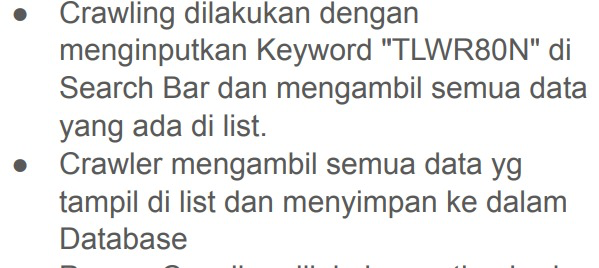

B.6 Menampilkan persentase nilai Selling Price dan Original Price yang memiliki value sama, karena pada statistik deskriptif nilai original price dan selling price ada indikasi kemiripan nilai 

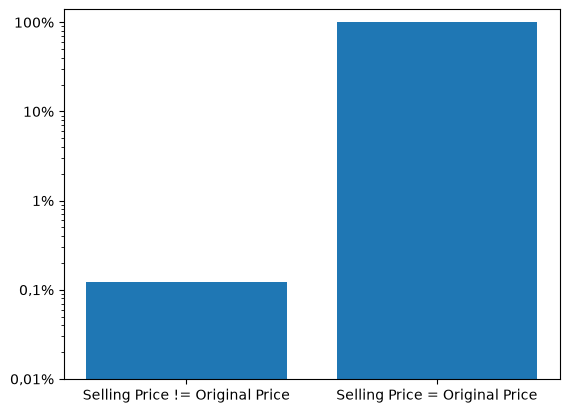

In [220]:
Persentase = df['Selling Price']==df['Original Price']
p = np.mean(Persentase)
data = [1-p, p]
plt.bar(['Selling Price != Original Price', 'Selling Price = Original Price'], data)
plt.yscale('log')
plt.yticks([1e-4, 1e-3, 1e-2, 1e-1, 1], ['0,01%', '0,1%', '1%', '10%', '100%'])
plt.show()

Berdasarkan hasil barplot di atas, persentase router dengan selling price yang berbeda dengan original price hanya 0,1% sedangkan untuk router selling price dan original price yang sama persentasenya 99,9%.

Hal ini mengindikasikan bahwa seller lebih sering menetapkan harga router yang tidak ada discount nya.

B.7 Menampilkan pairplot, untuk melihat pola pada data

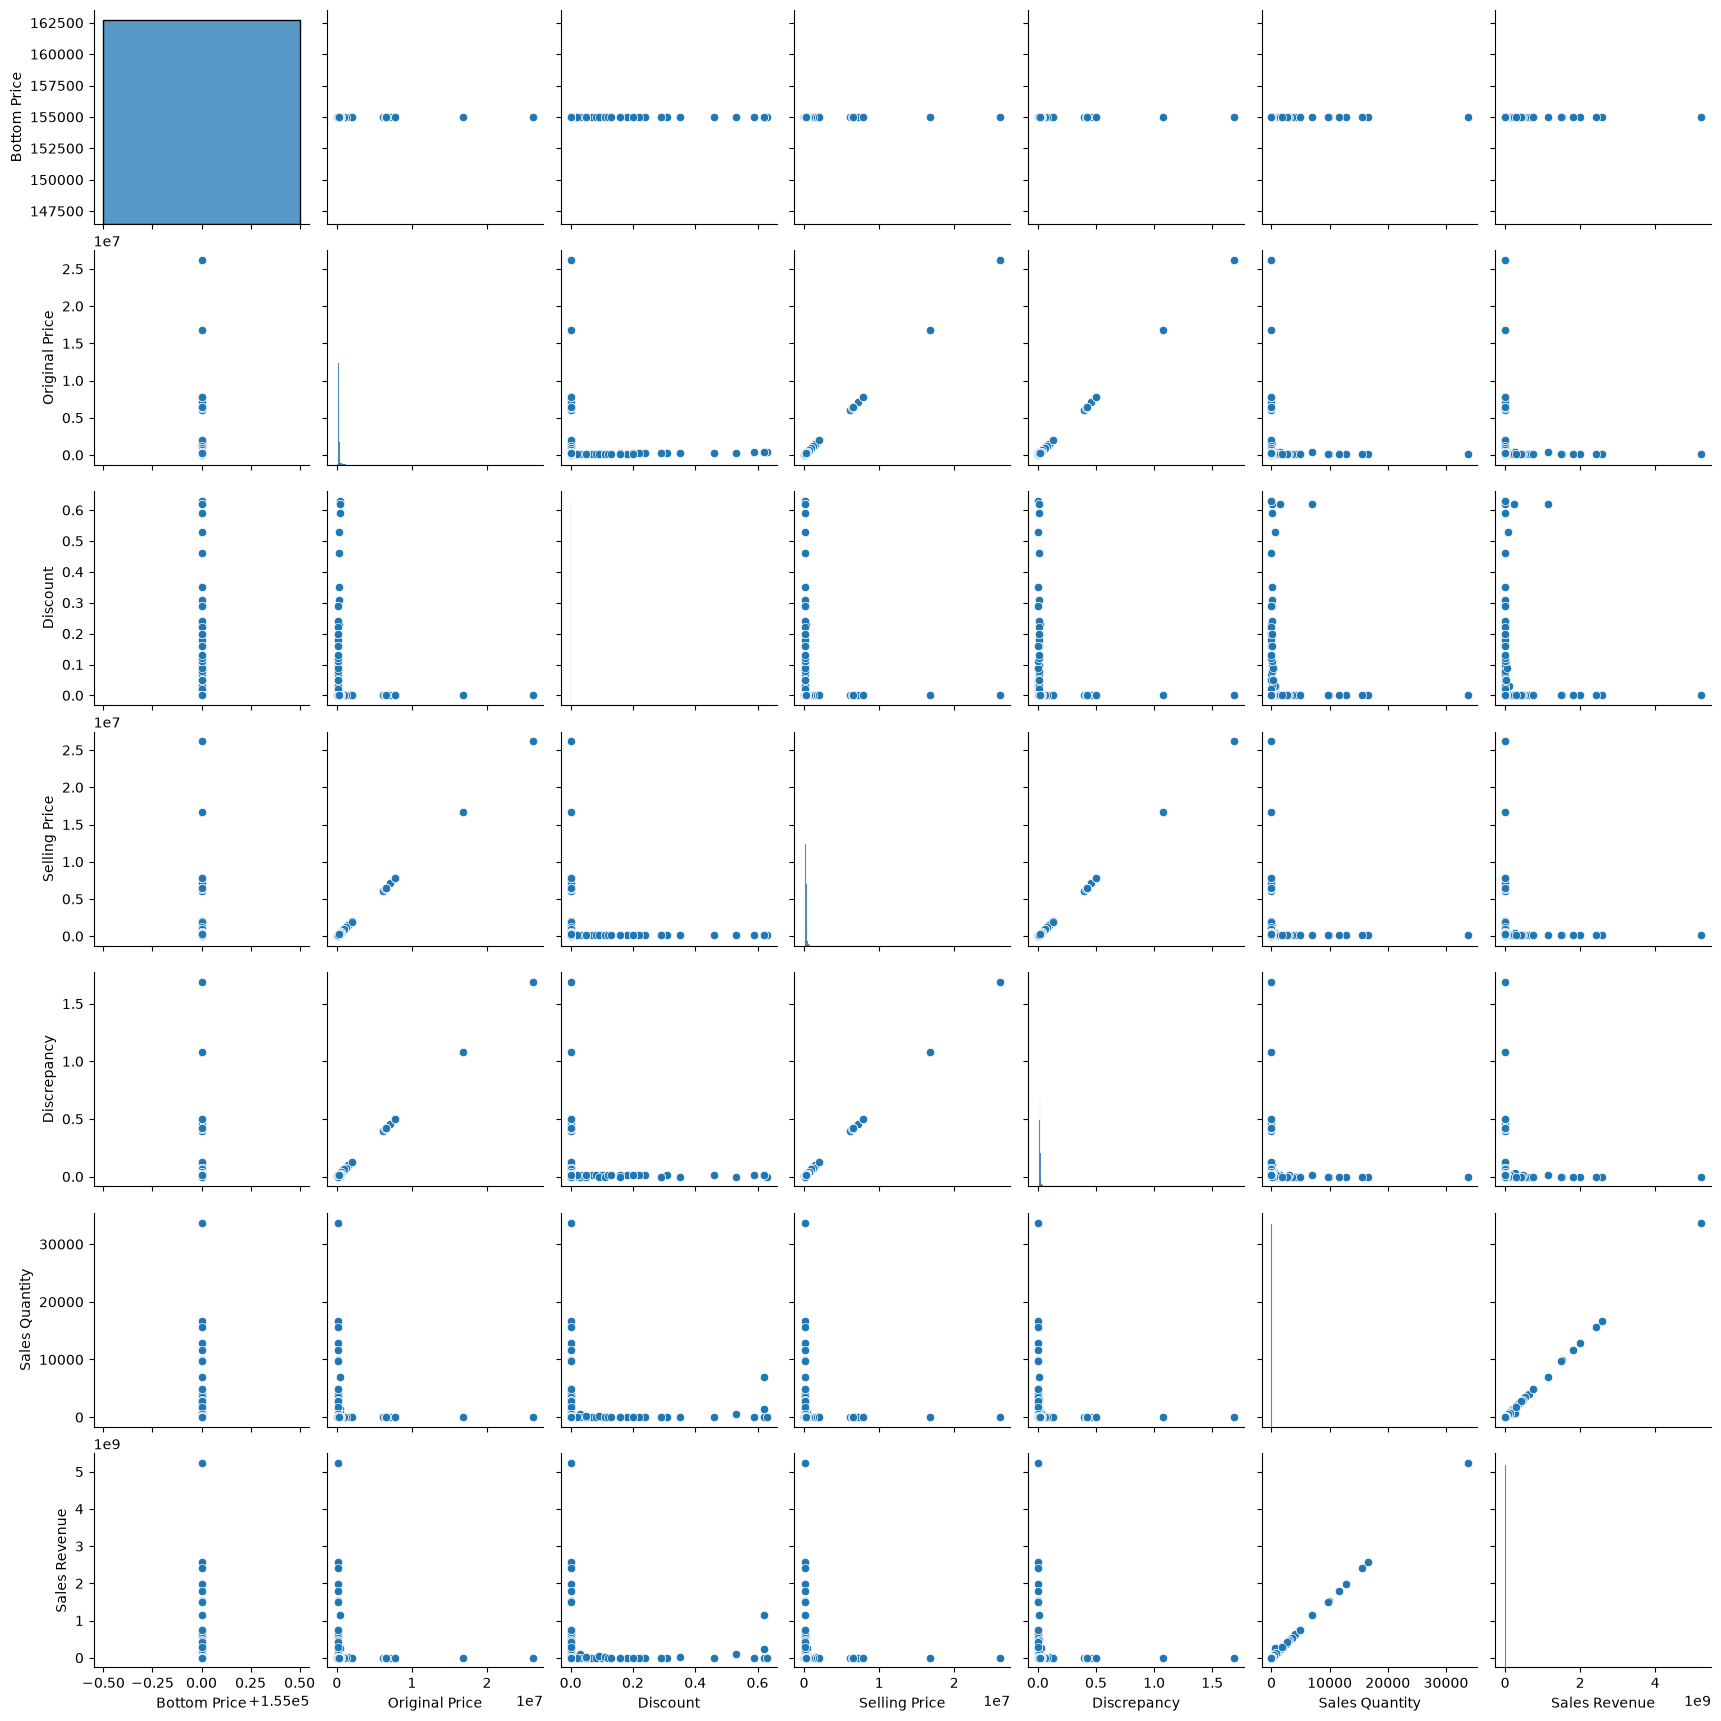

In [222]:
sns.pairplot(df.select_dtypes(include=[np.number]))

Berdasarkan hasil di atas, ada 3 pola data yang memiliki indikasi korelasi positif, yaitu:

- Sales Quantity vs Sales Revenue
- Selling Price vs Discrepancy
- Original Price vs Discrepancy
- Original Price vs Selling Price

Sehingga perlu analisis lebih lanjut yaitu menampilkan matrix korelasi

B.8 Menampilkan Heatmap, untuk melihat korelasi data

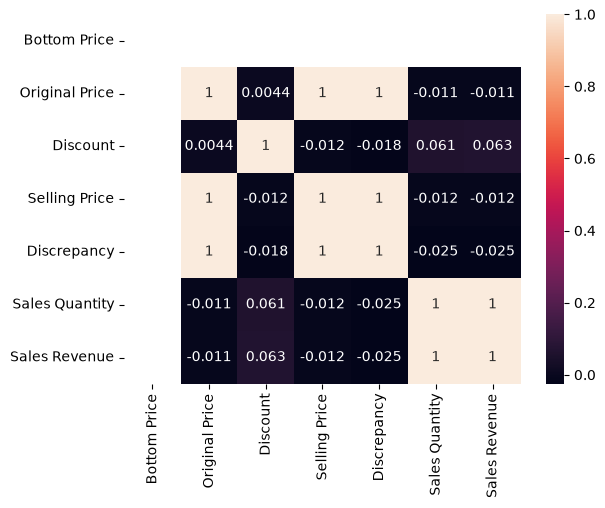

In [223]:
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True)
plt.show()

Berdasarkan hasil di atas :

- Sales Quantity vs Sales Revenue, memiliki tingkat korelasi di angka 1 yaitu sempurna
- Selling Price vs Discrepancy, memiliki tingkat korelasi di angka 1 yaitu sempurna
- Original Price vs Discrepancy, memiliki tingkat korelasi di angka 1 yaitu sempurna
- Original Price vs Selling Price, memiliki tingkat korelasi di angka 1 yaitu sempurna

Semua terlihat seperti coccok untuk di regressi karena memiliki tingkat korelasi 1 / sempurna. Namun jika dilihat seksama fitur-fitur tersebut seperti tidak masuk akal untuk di regresi. Alasannya :

- Untuk Sales Quantity vs Sales Revenue tidak cocok di regresi karena Sales Revenue tiap toko bergantung pada Sales Quantity dan Selling price toko tersebut, Jika masih dilanjutkan untuk regresi maka toko memiliki Sales Revenue yang sama meskipun Selling Price berbeda dengan toko yang lain.
- Untuk Selling Price vs Discrepancy tidak cocok di regresi karena jika ingin mencari Discrepancy dari Selling Price tidak masuk akal dan juga sebaliknya. Karena Discrepancy adalah rasio perbandingan antara Selling Price dengan Bottom Price dibagi 100
- Untuk Original Price vs Discrepancy sama tidak cocok di regresi alasannya pun sama seperti Selling Price vs Discrepancy.
- Original Price vs Selling Price tidak cocok untuk di regresi karena nilai kedua variabel tersebut hampir memiliki nilai yang sama seperti yang di tampilkan pada bar yang ada di atas.



Kesimpulan EDA:

Tidak ada data yang cocok untuk dilakukan prediksi harga produk router TLWR840N menggunakan algoritma Simple Linear Regression, namun kami tetap mencoba untuk melakukan regresi untuk variabel Original Price vs Selling Price 

# C. Pemodelan

C.1 Menentukan Variabel Independen dan Dependen

In [224]:
x = df['Original Price']
y = df['Selling Price']

C.2 Splitting data menjadi train dan test dengan rasio 80/20 menggunakan metode random

In [225]:
def split(df, x, y, size=0.8, random_state=42):
    df_tr = df.sample(frac=size, random_state=random_state)
    df_te = df.drop(df_tr.index)

    x_tr = df_tr[x].values.flatten()
    x_te = df_te[x].values.flatten()

    y_tr = df_tr[y].values.flatten()
    y_te = df_te[y].values.flatten()

    return x_tr, y_tr, x_te, y_te

In [226]:
x_tr, y_tr, x_te, y_te = split(df, x=['Original Price'], y='Selling Price')

C.3 Menampilkan Dimensi Data

In [227]:
print(x_tr.shape)
print(y_tr.shape)
print(x_te.shape)
print(y_te.shape)

(24261,)
(24261,)
(6065,)
(6065,)


C.4 Membuat Model Simple linear

Rumus Slope: Digunakan untuk mengukur seberapa besar nilai y jika nilai X bertambah 1 Unit

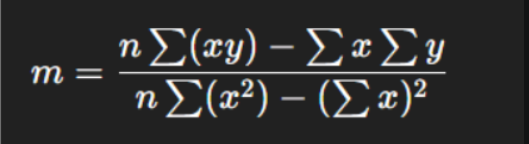

Rumus Intercept: Intercept Yaitu titik awal garis regresi untuk memotong sumbu Y, atau bisa dibilang titik awal nilai Y

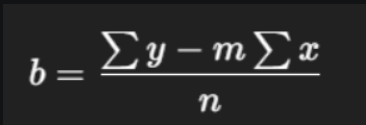

Prediksi

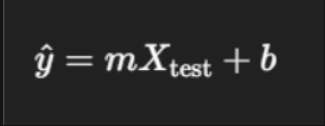

In [228]:
class SimpleLinear:

    #inisialisasi parameter slope dan intercept
    def __init__(self):
        self.slope = None # inisialisasi slope
        self.intercept = None # inisialisasi intercept

    # training model menggunakan method fit
    def fit(self, x, y):
        # mencari slope
        self.slope = (len(x) * np.sum(x * y) - np.sum(x) * np.sum(y)) / (len(x) * np.sum(x**2) - np.sum(x)**2)
        # mencari intercept
        self.intercept = (np.sum(y) - self.slope * np.sum(x)) / len(x)
        # print hasil slope dan intercept
        print(f'Slope : {self.slope}\n\n Intercept: {self.intercept} ')

    # prediksi model menggunakan method predict
    def predict(self, x):
        return self.slope * x + self.intercept

C.5 Inisialisasi Model

In [229]:
model = SimpleLinear()

C.6 Training Model

In [230]:
model.fit(x_tr, y_tr)

Slope : 0.9998618367665435

 Intercept: -63.532731331690464 


C.7 Prediksi Menggunakan Data Train

In [231]:
y_pred_tr = model.predict(x_tr)

C.8 Prediksi Menggunakan Data Test

In [232]:
y_pred_te = model.predict(x_te)

# D. Evaluasi

D.1 Membuat function evaluasi untuk melihat r2, mse, mae, rmse

r2: mengukur seberapa baik model menjelaskan variasi data (skala 0 - 1). makin dekat ke 1, artinya prediksi model makin akurat

mae: rata rata selisih absolut dari (y_asli - y_prediksi). menggambarkan rata rata error normal sehari hari

mse: rata rata nilai error (y_asli - y_prediksi) yang dikuadratkan, digunakan buat ngasih penalti besar ke tebakan yang meleset jauh (outlier)

rmse: nilai mse yang di akar kuadratin biar skalanya balik sama kaya data asli (rupiah)

In [233]:
def eval(y, y_pred):
    r2 = 1 - (np.sum((y - y_pred)**2) / np.sum((y - y.mean())**2)) 
    mse = np.mean((y - y_pred)**2)
    mae = np.mean(np.abs(y - y_pred))
    rmse = np.sqrt(mse)
    print(f'R2: {r2*100:.2f}')
    print(f'MSE: {mse}')
    print(f'MAE: {mae}')
    print(f'RMSE: {rmse}')

D.2 Evaluasi Untuk Data Train

In [234]:
eval(y_tr, y_pred_tr)

R2: 99.97
MSE: 19654044.264790796
MAE: 201.32252445877324
RMSE: 4433.28820005995


D.3 Evaluasi Untuk Data Test

In [235]:
eval(y_te, y_pred_te)

R2: 99.99
MSE: 2616007.670532357
MAE: 144.365440345321
RMSE: 1617.407700776881


D.4 Membuat Function Plot untuk menampilkan Garis Regresi, Actual vs Predicted, dan Residual Plot

In [236]:
def plot_evaluation(x, y, y_pred):
    residuals = y - y_pred

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    axes[0].scatter(x, y, color="blue", alpha=0.4, label="Data Asli")
    axes[0].plot(x, y_pred, color="red", linewidth=2, label="Garis Regresi")
    axes[0].set_title("1. Original Price vs Selling Price")
    axes[0].set_xlabel("Original Price (Rp)")
    axes[0].set_ylabel("Selling Price (Rp)")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.5)

    axes[1].scatter(y, y_pred, color="green", alpha=0.4)
    axes[1].plot(
        [y.min(), y.max()], [y.min(), y.max()], "r--", lw=2, label="Ideal (Y=X)"
    )
    axes[1].set_title("2. Y Actual vs Y Predicted")
    axes[1].set_xlabel("Selling Price Asli (Rp)")
    axes[1].set_ylabel("Selling Price Prediksi (Rp)")
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.5)

    axes[2].scatter(y_pred, residuals, color="purple", alpha=0.4)
    axes[2].axhline(y=0, color="red", linestyle="--", linewidth=2)
    axes[2].set_title("3. Residual Plot (Sebaran Error)")
    axes[2].set_xlabel("Selling Price Prediksi (Rp)")
    axes[2].set_ylabel("Residual / Error (Rp)")
    axes[2].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()

D.5 Plot Data Train

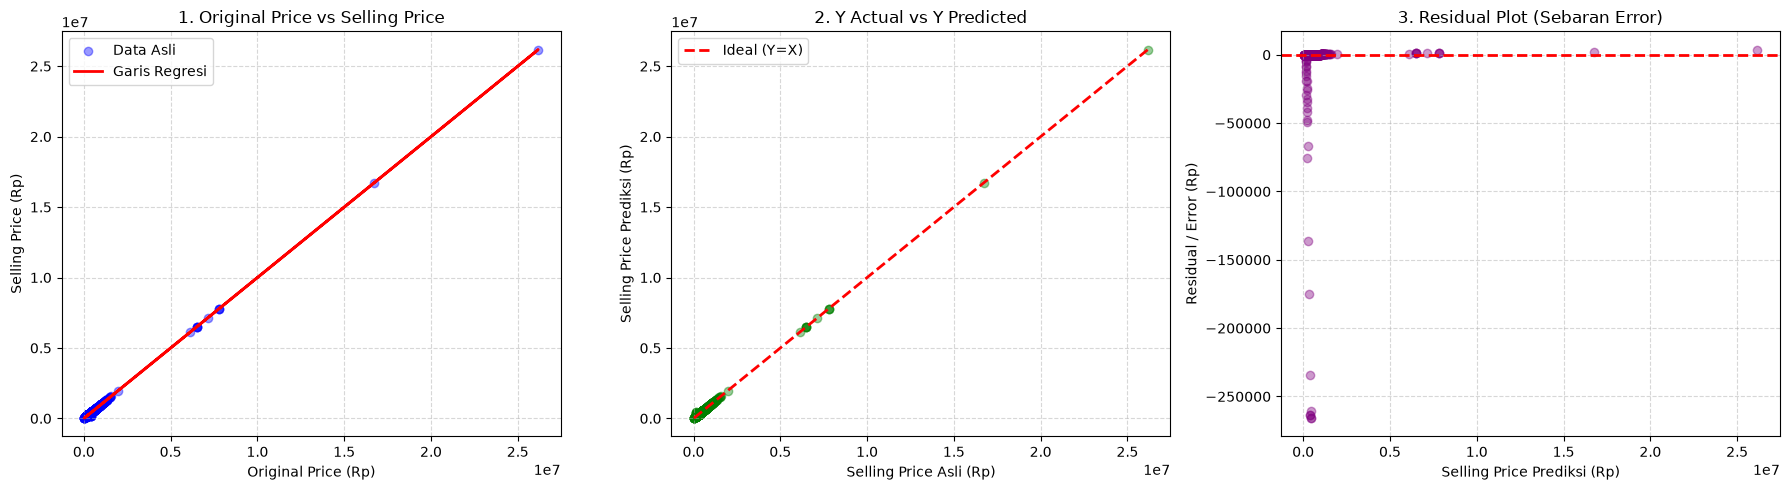

In [237]:
plot_evaluation(x_tr, y_tr, y_pred_tr)

D.6 Plot Data Test

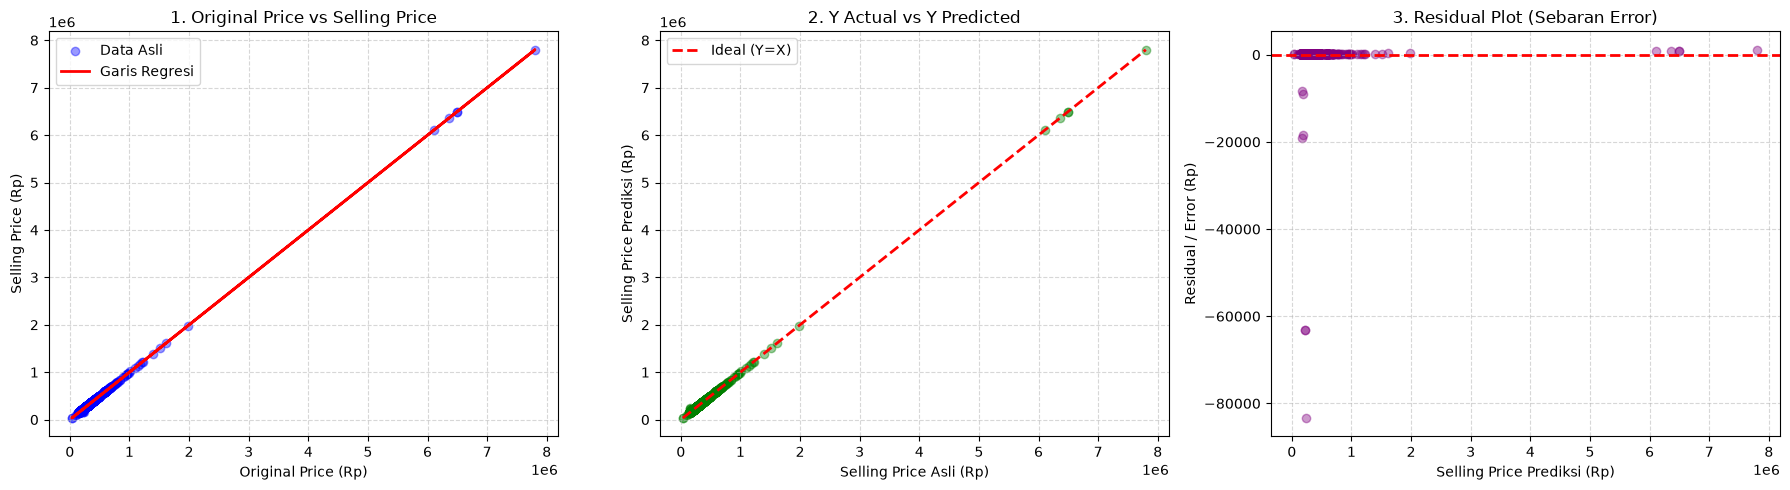

In [238]:
plot_evaluation(x_te, y_te, y_pred_te)

Berdasarkan hasil pemodelan regresi di atas, diperoleh hasil sebagai berikut:

- **R²** sebesar 99,99%, menunjukkan tingkat kesesuaian model yang sangat tinggi.
- **MSE** sebesar 2.616.007,67.
- **MAE** sebesar 144,36.
- **RMSE** sebesar 1.617,41.

Meskipun hasil evaluasi terlihat sangat bagus, model tersebut belum tentu cocok untuk digunakan dalam prediksi. Alasannya:

- Original Price dan Selling Price memiliki nilai yang hampir sama pada 99,9% data, sehingga model cenderung hanya mempelajari hubungan dari dua variabel yang hampir identik.
- Nilai R² yang tinggi belum tentu menunjukkan kemampuan model dalam memprediksi data baru.

# E. Kesimpulan

Model Simple Linear Regression belum dapat dikatakan valid untuk memprediksi harga jual produk TLWR840N. Untuk pengembangan selanjutnya, kami dapat mencoba pendekatan Time Series Forecasting menggunakan variabel Date untuk memperkirakan perubahan harga jual, dengan catatan diperlukan data historis yang lebih banyak.